# AA 279B HW 6 Prob 3

## Imports

In [76]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [77]:
import matlab.engine
from matlab.engine import MatlabEngine

# 1. Start the MATLAB process in the background
print("Starting MATLAB engine...")
eng: MatlabEngine = matlab.engine.start_matlab()

Starting MATLAB engine...


## Setup

In [78]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [79]:
import numpy as np
import pandas as pd
from numpy.linalg import norm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from tqdm import tqdm
import plotly.graph_objects as go
from datetime import datetime

from constants import DAY_TO_SEC, RAD_TO_SIDEREAL_HOUR, RAD_TO_DEG, MIN_TO_SEC, R_EARTH, MU_EARTH, R_SUN, C_LIGHT
from orbital import calc_theta_g, rv_HCI, ECI_from_HCI, cartesian_from_lla, lla_from_cartesian, calc_PCI_from_PCPF, calc_PCPF_from_PCI, spreading_loss
from dynamics import two_body
from spacetime import greg_to_jd, jd_to_greg
from angle import wrap_to_2pi, wrap_to_pi, angle_between, dcm_x, dcm_z
from utils import unit
from plotting import plot_3d, plot_earth_departure


In [80]:
MU_SUN = 1.3271244004193938e11  # km^3/s^2
ECLIPTIC_ANGLE = 23.45  # DEG

In [81]:
T_DEP_NOMINAL_JD = 2461333
T_ARR_NOMINAL_JD = 2461633

day_interval = 1
t_dep_jd = np.arange(2461261, 2461421, day_interval)
t_arr_jd = np.arange(2461489, 2461937, day_interval)
N_DEP = len(t_dep_jd)
N_ARR = len(t_arr_jd)

t_tot_jd = np.sort(np.concatenate((t_dep_jd, t_arr_jd)))

dep_grid_jd, arr_grid_jd = np.meshgrid(
    t_dep_jd,
    t_arr_jd,
    indexing="ij"
)
tof_grid_jd = arr_grid_jd - dep_grid_jd

In [82]:
np.ravel(rv_HCI(3, t_dep_jd[0], eng))

array([ 1.08381694e+08, -1.06130501e+08,  6.40766284e+03,  2.03569869e+01,
        2.11716293e+01, -1.27824387e-03])

In [1]:
rv_dep_earth_hci = np.array([np.ravel(rv_HCI(3, t, eng)) for t in t_dep_jd])
rv_arr_mars_hci = np.array([np.ravel(rv_HCI(4, t, eng)) for t in t_arr_jd])

NameError: name 'np' is not defined

In [84]:
# def departure_characteristics(v_dep_eci: np.ndarray):
#     v_dep_eci = np.asarray(v_dep_eci, dtype=np.complex128)
#     if not np.all(np.isfinite(v_dep_eci)) or np.max(np.abs(v_dep_eci.imag)) > 1e-9:
#         raise ValueError("Departure velocity must be finite and real")
#     v_dep_eci = v_dep_eci.real.astype(float)
#     C3 = norm(v_dep_eci)**2
#     rla = wrap_to_2pi(np.arctan2(v_dep_eci[1], v_dep_eci[0]))
#     dla = wrap_to_pi(np.arcsin(np.clip(v_dep_eci[2] / norm(v_dep_eci), -1, 1)))
#     return C3, rla, dla

def departure_characteristics(v_dep_eci: np.ndarray):
    C3 = norm(v_dep_eci)**2
    rla = wrap_to_2pi(np.arctan2(v_dep_eci[1], v_dep_eci[0]))
    dla = wrap_to_pi(np.arcsin(v_dep_eci[2] / norm(v_dep_eci)))
    return C3, rla, dla

def calc_transfer(r1_hci: np.ndarray, r2_hci: np.ndarray, tof_s: float):
    result = eng.AA279lambert_curtis(MU_SUN, r1_hci, r2_hci, "pro", "ignored", float(tof_s), nargout=2)
    v1_hci, v2_hci = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))

    
    velocities = np.concatenate((v1_hci, v2_hci))
    if not np.all(np.isfinite(velocities)):
        raise ValueError("Lambert returned non-finite velocities")
    # Could be numerical, so "real" it out
    imag_max = np.max(np.abs(velocities.imag))
    if imag_max > 1e-9:
        raise ValueError(f"Lambert returned complex velocities: max |imag| = {imag_max:.3g} km/s")

    return v1_hci.real, v2_hci.real


In [186]:
C3_grid = np.full((N_DEP, N_ARR), np.nan)
rla_grid = np.full((N_DEP, N_ARR), np.nan)
dla_grid = np.full((N_DEP, N_ARR), np.nan)
dv_tot = np.full((N_DEP, N_ARR, 3), np.nan)
v_arr_inf = np.full((N_DEP, N_ARR, 3), np.nan)

v1_grid = np.full((N_DEP, N_ARR, 3), np.nan)
v2_grid = np.full((N_DEP, N_ARR, 3), np.nan)

dcm_hci_wrt_eci = dcm_x(ECLIPTIC_ANGLE/RAD_TO_DEG)

failed_transfers = []
for dep_i in tqdm(range(N_DEP)):
    rv_dep = rv_dep_earth_hci[dep_i]
    for arr_i in range(N_ARR):
        rv_arr = rv_arr_mars_hci[arr_i]
        tof_jd = tof_grid_jd[dep_i, arr_i]
        try:
            v1, v2 = calc_transfer(rv_dep[:3], rv_arr[:3], tof_jd * DAY_TO_SEC)
        except (ValueError, matlab.engine.MatlabExecutionError) as exc:
            failed_transfers.append((t_dep_jd[dep_i], t_arr_jd[arr_i], str(exc)))
            print(f"Failed transfer: departure JD {t_dep_jd[dep_i]}, arrival JD {t_arr_jd[arr_i]}: {exc}")
            continue  # Grids retain NaN; failure does not imply no physical solution.

        v1_pci = v1 - rv_dep[3:6]  # Earth-relative, expressed in HCI axes
        v2_pci = v2 - rv_arr[3:6]  # Mars-relative, expressed in HCI axes
        v1_eci = dcm_hci_wrt_eci.T @ v1_pci
        C3, rla, dla = departure_characteristics(v1_eci)
        
        C3_grid[dep_i, arr_i] = C3
        rla_grid[dep_i, arr_i] = rla * RAD_TO_DEG
        dla_grid[dep_i, arr_i] = dla * RAD_TO_DEG
        v_arr_inf[dep_i, arr_i] = v2_pci
        v1_grid[dep_i, arr_i] = v1
        v2_grid[dep_i, arr_i] = v2

print(f"{len(failed_transfers)} failed transfers; see failed_transfers for dates and errors.")


100%|██████████| 160/160 [01:07<00:00,  2.36it/s]

0 failed transfers; see failed_transfers for dates and errors.


### Part b: C3 contours

In [109]:
# Grid is indexed [departure, arrival]; Plotly expects [y, x].
fig = go.Figure(go.Contour(
    x=t_dep_jd - T_DEP_NOMINAL_JD,
    y=t_arr_jd - T_ARR_NOMINAL_JD,
    z=C3_grid.T,
    contours={"start": 0, "end": 40, "size": 2, "coloring": "fill", "showlabels": True},
    line={"width": 1, "smoothing": 0},
    colorscale="Viridis",
    zmin=0, zmax=40,
    connectgaps=False,
    colorbar={"title": "C3 [km²/s²]"},
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>C3: %{z:.2f} km²/s²<extra></extra>",
))
fig.update_layout(
    title="Earth-to-Mars departure C3",
    xaxis_title=f"Earth departure [days from JD {T_DEP_NOMINAL_JD}]",
    yaxis_title=f"Mars arrival [days from JD {T_ARR_NOMINAL_JD}]",
    width=1200, height=800,
)
fig.show()
fig.write_image("plots_temp/earth-to-mars-c3.png", width=2000, height=1200, scale=2)

### Part c

In [110]:
fig = go.Figure(go.Contour(
    x=t_dep_jd - T_DEP_NOMINAL_JD,
    y=t_arr_jd - T_ARR_NOMINAL_JD,
    z=rla_grid.T,
    contours={"size": 10, "coloring": "fill", "showlabels": True},
    line={"width": 1, "smoothing": 0},
    colorscale="Viridis",
    connectgaps=False,
    colorbar={"title": "Right Ascension [º]"},
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>RLA: %{z:.2f}º<extra></extra>",
))
fig.update_layout(
    title="Earth-to-Mars departure Right Ascension",
    xaxis_title=f"Earth departure [days from JD {T_DEP_NOMINAL_JD}]",
    yaxis_title=f"Mars arrival [days from JD {T_ARR_NOMINAL_JD}]",
    width=1200, height=800,
)
fig.show()
fig.write_image("plots_temp/earth-to-mars-rla.png", width=2000, height=1200, scale=2)

### Part d

In [111]:
fig = go.Figure(go.Contour(
    x=t_dep_jd - T_DEP_NOMINAL_JD,
    y=t_arr_jd - T_ARR_NOMINAL_JD,
    z=dla_grid.T,
    contours={"size": 10, "coloring": "fill", "showlabels": True},
    line={"width": 1, "smoothing": 0},
    colorscale="Viridis",
    # zmin=0, zmax=360,
    connectgaps=False,
    colorbar={"title": "Declination [º]"},
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>DLA: %{z:.2f}º<extra></extra>",
))
fig.update_layout(
    title="Earth-to-Mars departure Declination",
    xaxis_title=f"Earth departure [days from JD {T_DEP_NOMINAL_JD}]",
    yaxis_title=f"Mars arrival [days from JD {T_ARR_NOMINAL_JD}]",
    width=1200, height=800,
)
fig.show()
fig.write_image("plots_temp/earth-to-mars-dla.png", width=2000, height=1200, scale=2)

### Part e

In [112]:
v_arr_inf_norm = norm(v_arr_inf, axis=2)

fig = go.Figure(go.Contour(
    x=t_dep_jd - T_DEP_NOMINAL_JD,
    y=t_arr_jd - T_ARR_NOMINAL_JD,
    z=v_arr_inf_norm.T,
    contours={"size": 10, "coloring": "fill", "showlabels": True},
    line={"width": 1, "smoothing": 0},
    colorscale="Viridis",
    zmin=0, zmax=10,
    connectgaps=False,
    colorbar={"title": "Arrival Excess Speed [km/s]"},
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>DLA: %{z:.2f}º<extra></extra>",
))
fig.update_layout(
    title="Mars Arrival Excess Speed",
    xaxis_title=f"Earth departure [days from JD {T_DEP_NOMINAL_JD}]",
    yaxis_title=f"Mars arrival [days from JD {T_ARR_NOMINAL_JD}]",
    width=1200, height=800,
)
fig.show()
fig.write_image("plots_temp/earth-to-mars-v-arr-inf.png", width=2000, height=1200, scale=2)

### Part f

In [ ]:
ARR_JD = 2461633
C3_MAX = 15.0  # km/s
DLA_MAX = 33.0  # deg
V_ARR_MAX = 3.5  # km/s

C3_mask = C3_grid.copy()
C3_mask[C3_grid > C3_MAX] = np.nan
C3_mask[dla_grid > DLA_MAX] = np.nan
C3_mask[v_arr_inf_norm > V_ARR_MAX] = np.nan

# dv_limited = dv1_arr.copy()
# dv_limited[dv_limited > MAX_DV] = np.nan

In [151]:
# Grid is indexed [departure, arrival]; Plotly expects [y, x].
fig = go.Figure(go.Contour(
    x=t_dep_jd - T_DEP_NOMINAL_JD,
    y=t_arr_jd - T_ARR_NOMINAL_JD,
    z=C3_mask.T,
    contours={"start": 0, "end": 40, "size": 2, "coloring": "fill", "showlabels": True},
    line={"width": 1, "smoothing": 0},
    colorscale="Viridis",
    zmin=0, zmax=40,
    connectgaps=False,
    colorbar={"title": "C3 [km²/s²]"},
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>C3: %{z:.2f} km²/s²<extra></extra>",
))
fig.update_layout(
    title="Earth-to-Mars departure C3 with Constraints",
    xaxis_title=f"Earth departure [days from JD {T_DEP_NOMINAL_JD}]",
    yaxis_title=f"Mars arrival [days from JD {T_ARR_NOMINAL_JD}]",
    width=1200, height=800,
)
fig.update_traces(hoverongaps=False)
fig.show()
# fig.write_image("plots_temp/earth-to-mars-constriants.png", width=2000, height=1200, scale=2)

In [152]:
C3_mask = C3_mask[:,abs(t_arr_jd - T_ARR_NOMINAL_JD) == 0].reshape(-1)
C3_constrained = C3_mask[~np.isnan(C3_mask)]
t_dep_constrainted = t_dep_jd[~np.isnan(C3_mask)]

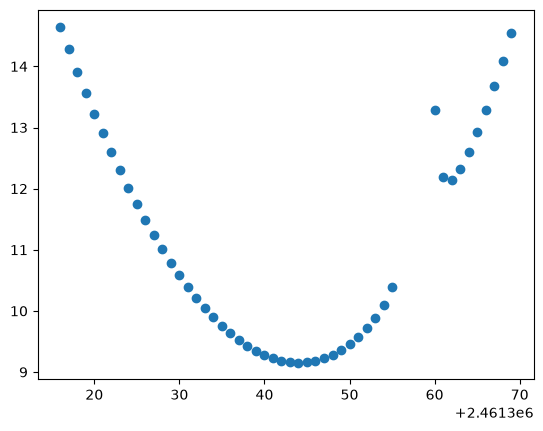

In [ ]:
plt.scatter(t_dep_constrainted, C3_constrained)

In [185]:
import juliandate as jd

dates = np.sort(t_dep_constrainted)
groups = np.split(dates, np.flatnonzero(np.diff(dates) > day_interval) + 1)
for g in groups:
    if g.size: 
        print(f"JD {g[0]}–{g[-1]}: {len(g)} consecutive dates")
        d1 = datetime(*jd.to_gregorian(g[0]))
        d2 = datetime(*jd.to_gregorian(g[-1]))
        print(f"\t{d1.strftime('%F')} — {d2.strftime('%F')}")

JD 2461316–2461355: 40 consecutive dates
	2026-10-02 — 2026-11-10
JD 2461360–2461369: 10 consecutive dates
	2026-11-15 — 2026-11-24
